# Практична робота 22. Часові ряди: ковзне середнє, декомпозиція та прогноз
**Варіант 1 (м. Київ)**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.stats import linregress

np.random.seed(1)
base_temp = 9.5
amplitude = 14.0
trend_per_year = 0.04
noise_scale = 1.0
city = "Київ"
n_years = 10

dates = pd.date_range(start="2015-01-01", periods=n_years * 12, freq="MS")
month = dates.month
years_elapsed = (dates.year - dates.year[0]) + (dates.month - 1) / 12

seasonal = amplitude * np.cos((month - 7) / 12 * 2 * np.pi)
trend = trend_per_year * years_elapsed
noise = np.random.normal(0, noise_scale, len(dates))
temp = np.round(base_temp + trend + seasonal + noise, 1)

climate_ts = pd.Series(temp, index=dates, name="температура")
print(f"Загальна кількість спостережень: {len(climate_ts)}")
print(climate_ts.head(12))

Загальна кількість спостережень: 120
2015-01-01    -2.9
2015-02-01    -3.2
2015-03-01     2.0
2015-04-01     8.4
2015-05-01    17.4
2015-06-01    19.3
2015-07-01    25.3
2015-08-01    20.9
2015-09-01    16.8
2015-10-01     9.3
2015-11-01     4.0
2015-12-01    -4.6
Freq: MS, Name: температура, dtype: float64


## Завдання 1. Побудова багаторічного ряду власного варіанта

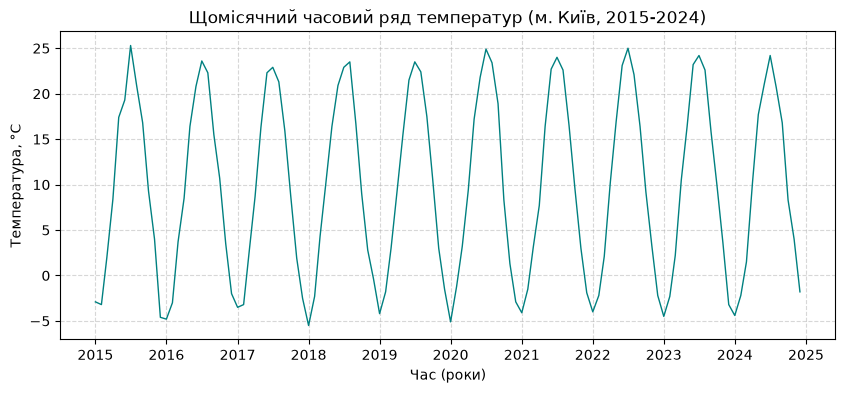

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(climate_ts.index, climate_ts.values, color="teal", linewidth=1)
ax.set_xlabel("Час (роки)")
ax.set_ylabel("Температура, °C")
ax.set_title("Щомісячний часовий ряд температур (м. Київ, 2015-2024)")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()

## Завдання 2. Ковзне середнє при різних вікнах

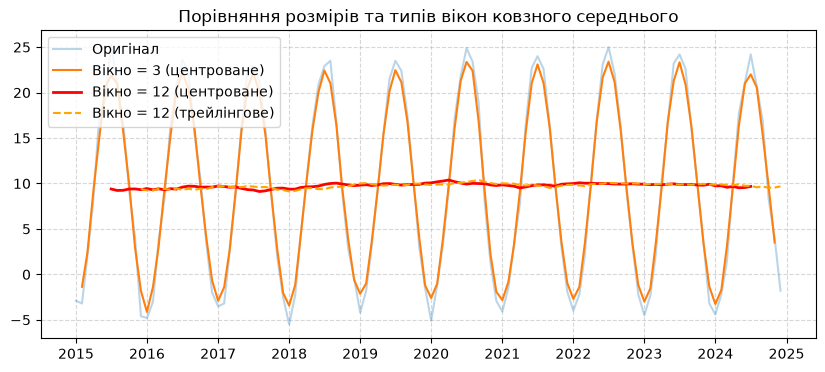

In [3]:
ma3 = climate_ts.rolling(window=3, center=True).mean()
ma12_centered = climate_ts.rolling(window=12, center=True).mean()
ma12_trailing = climate_ts.rolling(window=12, center=False).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(climate_ts.index, climate_ts.values, alpha=0.3, label="Оригінал")
ax.plot(climate_ts.index, ma3.values, label="Вікно = 3 (центроване)")
ax.plot(climate_ts.index, ma12_centered.values, color="red", linewidth=2, label="Вікно = 12 (центроване)")
ax.plot(climate_ts.index, ma12_trailing.values, color="orange", linestyle="--", label="Вікно = 12 (трейлінгове)")
ax.legend()
ax.set_title("Порівняння розмірів та типів вікон ковзного середнього")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()

## Завдання 3. Декомпозиція seasonal_decompose

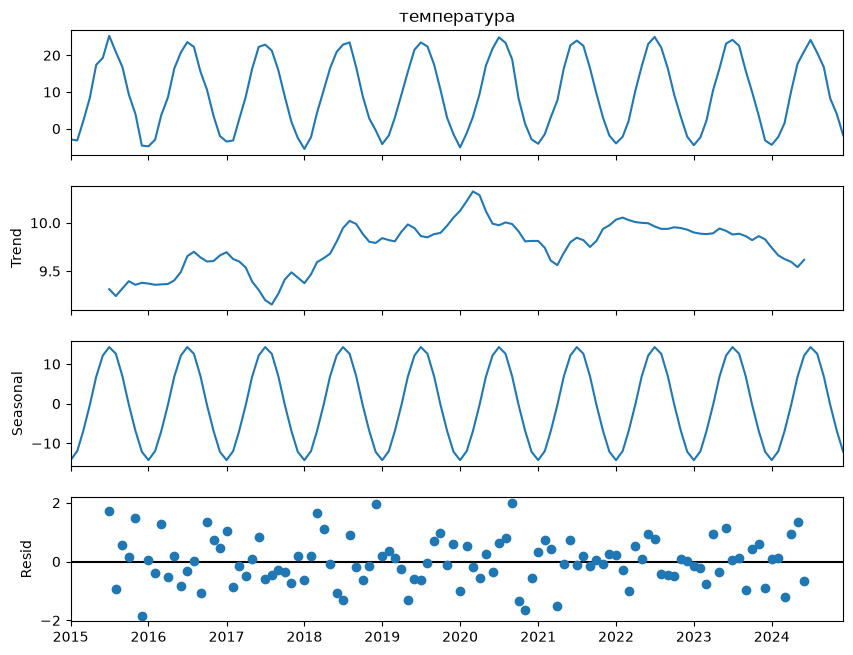

Стандартне відхилення залишку (resid std): 0.7869 (заданий шум σ = 1.0)


In [4]:
decomposition = seasonal_decompose(climate_ts, model="additive", period=12)
fig = decomposition.plot()
fig.set_size_inches(9, 7)
plt.show()

resid_std = decomposition.resid.dropna().std()
print(f"Стандартне відхилення залишку (resid std): {resid_std:.4f} (заданий шум σ = {noise_scale})")

## Завдання 4. Прогноз на N місяців уперед

Прогноз на 12 місяців уперед:
2025-01-01    -4.2
2025-02-01    -1.9
2025-03-01     3.1
2025-04-01     9.7
2025-05-01    16.9
2025-06-01    22.2
2025-07-01    24.3
2025-08-01    22.7
2025-09-01    17.0
2025-10-01     9.8
2025-11-01     3.2
2025-12-01    -2.0
Freq: MS, dtype: float64


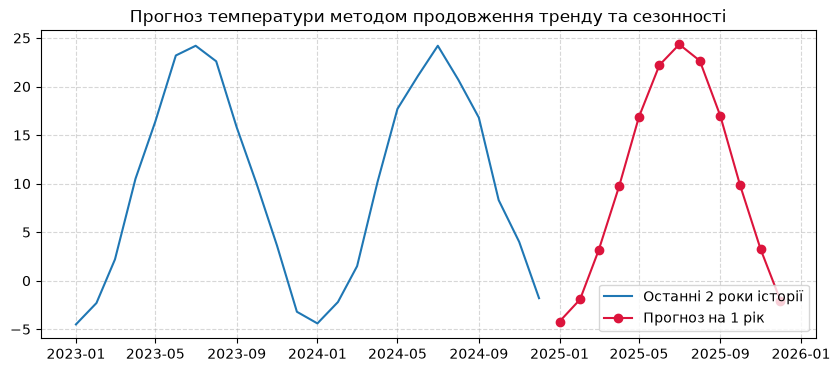

In [5]:
t = np.arange(len(climate_ts))
known_idx = decomposition.trend.notna().values
trend_fit = linregress(t[known_idx], decomposition.trend[known_idx])

n_ahead = 12  # прогноз на рік уперед
t_future = np.arange(len(climate_ts), len(climate_ts) + n_ahead)
trend_forecast = trend_fit.intercept + trend_fit.slope * t_future

seasonal_by_month = decomposition.seasonal.groupby(decomposition.seasonal.index.month).mean()
future_dates = pd.date_range(climate_ts.index[-1] + pd.offsets.MonthBegin(1), periods=n_ahead, freq="MS")
seasonal_forecast = seasonal_by_month.reindex(future_dates.month).values

forecast = pd.Series(trend_forecast + seasonal_forecast, index=future_dates)
print("Прогноз на 12 місяців уперед:")
print(forecast.round(1))

# Візуалізація прогнозу
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(climate_ts.index[-24:], climate_ts.values[-24:], label="Останні 2 роки історії")
ax.plot(forecast.index, forecast.values, color="crimson", marker="o", label="Прогноз на 1 рік")
ax.legend()
ax.set_title("Прогноз температури методом продовження тренду та сезонності")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()

## Завдання 5. Статистична значущість тренду

In [6]:
deseason = climate_ts - decomposition.seasonal
t_years = np.arange(len(climate_ts)) / 12
trend_test = linregress(t_years, deseason.values)

print(f"Оцінений нахил: {trend_test.slope:.4f} °C/рік (очікувано ~0.04)")
print(f"Стандартна похибка (stderr): {trend_test.stderr:.4f}")
print(f"p-value: {trend_test.pvalue:.4e}")

# 95% довірчий інтервал для нахилу
ci_low = trend_test.slope - 1.96 * trend_test.stderr
ci_high = trend_test.slope + 1.96 * trend_test.stderr
print(f"95% довірчий інтервал для нахилу: ({ci_low:.4f}, {ci_high:.4f})")

Оцінений нахил: 0.0473 °C/рік (очікувано ~0.04)
Стандартна похибка (stderr): 0.0274
p-value: 8.7349e-02
95% довірчий інтервал для нахилу: (-0.0065, 0.1010)
